# Visualizing Simulation Results 
This code was used to create Figures 6 and 7 in the manuscript

In [ ]:
import sys
sys.path.append('../../')
from utils import plotting_utils
import pickle
import jax.numpy as jnp

In [ ]:
import numpy as np

def runoff_onset(dbs, threshold=0.0):
    onset = {}
    final_cumflow = {}
    cumflow_150 = {}
    for parametrization, db in dbs.items():
        print("=======================================================")
        times, q_top, q_bottom, q_surf = plotting_utils.exit_fluxes(db,cumulative=True)
        onset[parametrization] = {}
        final_cumflow[parametrization] = {}
        cumflow_150[parametrization] = {}
        for key, q in [("surf", q_surf), ("top", q_top), ("bottom",q_bottom)]:
            above = np.nonzero(q > threshold)[0]
            onset[parametrization][key] = round(float(times[above[0]]),0) if len(above) else None
            final_cumflow[parametrization][key] = float(q[-1]) 
            cumflow_150[parametrization][key] = float(q[np.argmin(np.abs(times - 150))])

        print(f"Start of flow for {parametrization:15s}     surface runoff: {onset[parametrization]['surf']} d  interflow: {onset[parametrization]['top']} d  gw discharge: {onset[parametrization]['bottom']} d")
        print(f"Cum. flow at day 150 {parametrization:15s}  surface runoff: {round(cumflow_150[parametrization]['surf'],2)} m²  interflow: {round(cumflow_150[parametrization]['top'],2)} m²  gw discharge: {round(cumflow_150[parametrization]['bottom'],2)} m²")
        print(f"Final cum. flow {parametrization:15s}       surface runoff: {round(final_cumflow[parametrization]['surf'],2)} m²  interflow: {round(final_cumflow[parametrization]['top'],2)} m²  gw discharge: {round(final_cumflow[parametrization]['bottom'],2)} m²")
        total = final_cumflow[parametrization]['surf'] + final_cumflow[parametrization]['top'] + final_cumflow[parametrization]['bottom']
        print(f"Final partitioning {parametrization:15s}   surface runoff: {round(final_cumflow[parametrization]['surf']/total*100)}%   interflow: {round(final_cumflow[parametrization]['top']/total*100)}%  gw discharge: {round(final_cumflow[parametrization]['bottom']/total*100)}%")
    return onset, final_cumflow

# Idealized BC

In [ ]:
input_folder = '../../output/idealized/'

In [ ]:
constant_files = {
    "drying": "drying.pkl",
    "drying_omega10": "drying_omega10.pkl",
    "imp10": "imp10.pkl",
    "imp50": "imp50.pkl",
    "cap": "cap.pkl",
}

constant_dbs = {}
for parametrization, filename in constant_files.items():
    with open(input_folder + filename, 'rb') as pickle_file:
        constant_dbs[parametrization] = pickle.load(pickle_file)


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


### Overview over ice content in domain

In [ ]:
for idx,parametrization in enumerate(constant_dbs):
    print("================================")
    print(parametrization)
    theta_i_total = constant_dbs[parametrization]["theta_i_total"]
    max_theta_i = 0
    av_max = 0
    nz, nx = jnp.shape(theta_i_total[0])
    for i in range(len(theta_i_total)):
        av_max_i = jnp.sum(theta_i_total[i][nz//2:,:])/(nz//2*nx)
        if jnp.max(theta_i_total[i])>max_theta_i:
            id_max = i
            max_theta_i = jnp.max(theta_i_total[i])
        if av_max_i>av_max:
            av_max = av_max_i
            id_av_max = i
    print("================================")
    print("Maximum theta_i:", jnp.round(id_max/12), round(float(max_theta_i),2))
    print("Average maximum:", jnp.round(id_av_max/12), round(float(av_max),2))
    print("Final time step, maximum:", i/12, round(float(jnp.max(theta_i_total[-1])),2),"\n")
    

drying
Maximum theta_i: 57.0 0.18
Average maximum: 80.0 0.09
Final time step, maximum: 130.0 0.03 

drying_omega10
Maximum theta_i: 78.0 0.16
Average maximum: 78.0 0.07
Final time step, maximum: 130.0 0.02 

imp10
Maximum theta_i: 80.0 0.16
Average maximum: 79.0 0.08
Final time step, maximum: 130.0 0.04 

imp50
Maximum theta_i: 78.0 0.16
Average maximum: 81.0 0.06
Final time step, maximum: 130.0 0.02 

cap
Maximum theta_i: 70.0 0.29
Average maximum: 90.0 0.1
Final time step, maximum: 130.0 0.18 



In [ ]:
constant_onset, final_cumflow = runoff_onset(constant_dbs,threshold=0.01)

Start of flow for drying              surface runoff: 37.0 d  interflow: 96.0 d  gw discharge: 1.0 d
Cum. flow at day 150 drying           surface runoff: 0.71 m²  interflow: 0.08 m²  gw discharge: 1.2 m²
Final cum. flow drying                surface runoff: 0.71 m²  interflow: 0.08 m²  gw discharge: 1.2 m²
Final partitioning drying            surface runoff: 36%   interflow: 4%  gw discharge: 60%
Start of flow for drying_omega10      surface runoff: 31.0 d  interflow: 100.0 d  gw discharge: 1.0 d
Cum. flow at day 150 drying_omega10   surface runoff: 0.9 m²  interflow: 0.16 m²  gw discharge: 0.89 m²
Final cum. flow drying_omega10        surface runoff: 0.9 m²  interflow: 0.16 m²  gw discharge: 0.89 m²
Final partitioning drying_omega10    surface runoff: 46%   interflow: 8%  gw discharge: 45%
Start of flow for imp10               surface runoff: None d  interflow: None d  gw discharge: 1.0 d
Cum. flow at day 150 imp10            surface runoff: 0.0 m²  interflow: 0.0 m²  gw discharge: 1

### Create Figure 5.1

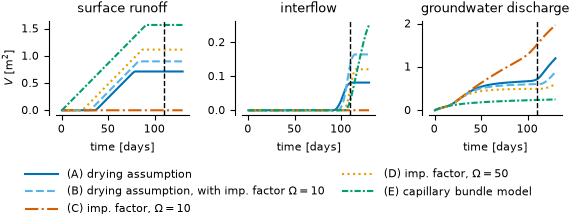

In [ ]:
index = 12*110
cm = 1/2.54  # centimeters in inches
fig, axes = plotting_utils.plot_cumulative_partitioning_grid(constant_dbs,figsize=(15*cm,6*cm),index=index)
fig.savefig(f"../../figures/results/idealized/idealized_cum.png", dpi=1000, bbox_inches="tight")

/home/anne/anaconda3/envs/cryorich_AD/lib/python3.12/site-packages/matplotlib/patches.py:3582: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist


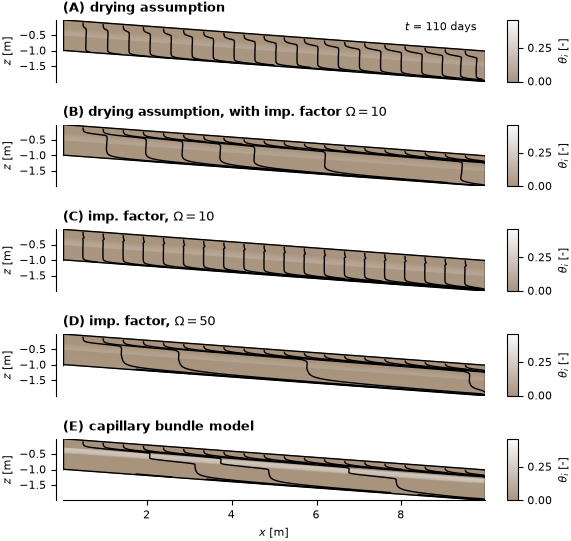

In [ ]:
fig, axes = plotting_utils.plot_streamlines_grid(constant_dbs, index, slope=-0.1,figsize=(15*cm,13.41*cm),cum=False)
fig.savefig(f"../../figures/results/idealized/idealized_110d_streamlines.png", dpi=1000, bbox_inches="tight")

### Temperature distribution     

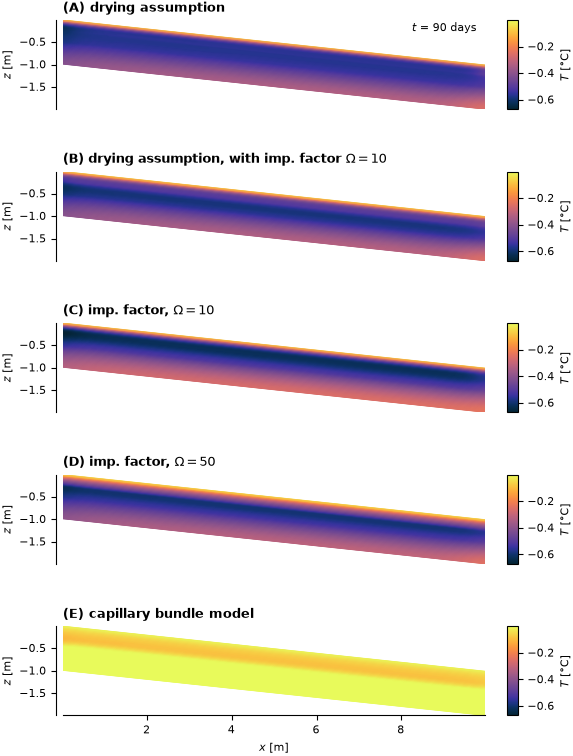

In [ ]:
index = 90*12
fig, axes = plotting_utils.plot_T_grid(constant_dbs, index, field_key="T_total",figsize=(15*cm,19.41*cm))
fig.savefig(f"../../figures/results/idealized/idealized_{index//12}d_T.png", dpi=1000, bbox_inches="tight")

# ERA5-Land BC Simulation

In [ ]:
input_folder = '../../output/simulation/simulation_'


In [ ]:
era5_files = {
    "drying": "drying.pkl",
    "drying_omega10": "drying_omega10.pkl",
    "imp10": "imp10.pkl",
    "imp50": "imp50.pkl",
    "cap": "cap.pkl",
}

era5_dbs = {}
for parametrization, filename in era5_files.items():
    with open(input_folder + filename, 'rb') as pickle_file:
        era5_dbs[parametrization] = pickle.load(pickle_file)


### Overview over ice content in domain

In [ ]:
for idx,parametrization in enumerate(era5_dbs):
    print("================================")
    print(parametrization)
    theta_i_total = era5_dbs[parametrization]["theta_i_total"]
    max_theta_i = 0
    av_max = 0
    nz, nx = jnp.shape(theta_i_total[0])
    for i in range(len(theta_i_total)):
        av_max_i = jnp.sum(theta_i_total[i][nz//2:,:])/(nz//2*nx)
        if jnp.max(theta_i_total[i])>max_theta_i:
            id_max = i
            max_theta_i = jnp.max(theta_i_total[i])
        if av_max_i>av_max:
            av_max = av_max_i
            id_av_max = i
    print("================================")
    print("Maximum theta_i:", jnp.round(id_max), round(float(max_theta_i),2))
    print("Average maximum:", jnp.round(id_av_max), round(float(av_max),2))
    print("Final time step, maximum:", i, round(float(jnp.max(theta_i_total[-1])),2),"\n")


drying
Maximum theta_i: 179 0.19
Average maximum: 186 0.13
Final time step, maximum: 212 0.0 

drying_omega10
Maximum theta_i: 181 0.18
Average maximum: 194 0.1
Final time step, maximum: 212 0.0 

imp10
Maximum theta_i: 179 0.18
Average maximum: 186 0.11
Final time step, maximum: 212 0.0 

imp50
Maximum theta_i: 179 0.19
Average maximum: 179 0.08
Final time step, maximum: 212 0.0 

cap
Maximum theta_i: 194 0.32
Average maximum: 182 0.17
Final time step, maximum: 212 0.04 



In [ ]:
era5_onset, era5_final_cumflow = runoff_onset(era5_dbs,0.001)

Start of flow for drying              surface runoff: 4.0 d  interflow: 163.0 d  gw discharge: 2.0 d
Cum. flow at day 150 drying           surface runoff: 0.04 m²  interflow: 0.0 m²  gw discharge: 0.21 m²
Final cum. flow drying                surface runoff: 0.66 m²  interflow: 1.4 m²  gw discharge: 0.71 m²
Final partitioning drying            surface runoff: 24%   interflow: 51%  gw discharge: 26%
Start of flow for drying_omega10      surface runoff: 4.0 d  interflow: 188.0 d  gw discharge: 2.0 d
Cum. flow at day 150 drying_omega10   surface runoff: 0.2 m²  interflow: 0.0 m²  gw discharge: 0.19 m²
Final cum. flow drying_omega10        surface runoff: 1.73 m²  interflow: 0.66 m²  gw discharge: 0.47 m²
Final partitioning drying_omega10    surface runoff: 60%   interflow: 23%  gw discharge: 17%
Start of flow for imp10               surface runoff: 4.0 d  interflow: 164.0 d  gw discharge: 2.0 d
Cum. flow at day 150 imp10            surface runoff: 0.02 m²  interflow: 0.0 m²  gw discharge:

### Create Figure 7

/home/anne/Dokumente/Promotion/Code/CryoRich_AD/notebooks/creating_figures/../../utils/plotting_utils.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


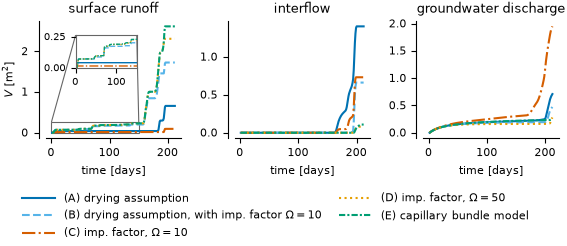

In [ ]:
fig, axes = plotting_utils.plot_cumulative_partitioning_grid_with_inset(era5_dbs,figsize=(15*cm,6.6*cm))
fig.savefig(f"../../figures/results/simulation/sim_cum.png", dpi=1000)

### Temperature distribution     

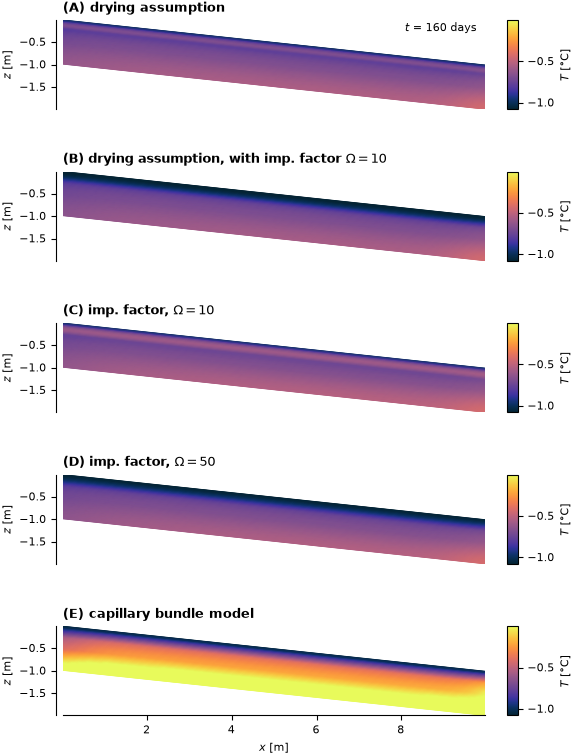

In [ ]:
index = 160
fig, axes = plotting_utils.plot_T_grid(era5_dbs, index, field_key="T_total",figsize=(15*cm,19.41*cm))
fig.savefig(f"../../figures/results/simulation/sim_{index}d_T.png",dpi=1000)